# 40 · Assumptions vs reality, and what didn't work

**Question.** Which assumptions does the GridPilot result rest on, how does reality differ from each one, which of them did we test, and what did not work?

**How to read it.** This notebook runs no simulation and reads no grid data. It reads only the committed `results/*.json` files, and every number below is read from them, never typed, with its evidence label (`assumed`, `measured`, `modeled`, `observed`, `simulated`). Savings are against U (every job runs in Utah as it arrives), with the registered 4-week block 95% intervals in brackets, on the validation year (the sealed test year is not read). The same register and results are exported to `results/assumptions.json` (§6) for the dashboard's Method drawer.

**Short answer** (the numbers are printed in §0's last cell):
- The saving comes from **moving** work, and it depends on two assumptions most of all: that large jobs can move, and that spare remote capacity exists. Limit moves to jobs of 8 GPUs or fewer, or take the remote slots away, and most of it is gone.
- **Waiting in Utah** barely helps, a carbon-blind router (G) saves about nothing, the learned forecast does not beat the weekly one (H2 inconclusive), and no dynamic search beats the fixed clean-region ranking (H3 not supported).
- **Even perfect carbon foresight** (H) does not beat the fixed ranking S, so weather-aware forecasts are unlikely to change the routing result.
- Two bookkeeping choices decide a sign: on a flat marginal factor, storage **adds** CO₂; and counting hydro reservoir evaporation turns moving work from a water saving into a water cost.

## 0. Inputs

In [1]:
import hashlib
import json
import re
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

from gridpilot import notebook as nb
from gridpilot.paths import REPO_ROOT, RESULTS_DIR
from gridpilot.results import env, validate_artifact, write_json_atomic

nb.setup()
pl.Config.set_fmt_str_lengths(400)
pl.Config.set_tbl_width_chars(400)

FILES = ["manifest.json", "metrics.json", "extensions.json", "storage.json", "job-replay.json",
         "grid-profile.json"]
SRC = {f: json.loads((RESULTS_DIR / f).read_text()) for f in FILES}
SHA = {f: hashlib.sha256((RESULTS_DIR / f).read_bytes()).hexdigest() for f in FILES}

# The water illustration (T14, PR #69) is not merged yet: read the committed file once it is on
# main, otherwise the PR branch's committed file. Without either, its row is marked pending.
WATER_REF = "origin/s3/t14-water"
WATER_PR = "PR #69"
if (RESULTS_DIR / "water.json").exists():
    water_text, WATER_FROM = (RESULTS_DIR / "water.json").read_text(), "results/water.json"
else:
    r = subprocess.run(["git", "show", f"{WATER_REF}:results/water.json"], cwd=REPO_ROOT,
                       capture_output=True, text=True, check=False)
    water_text = r.stdout if r.returncode == 0 else None
    WATER_FROM = f"{WATER_REF}:results/water.json ({WATER_PR}, pending merge)" if water_text else None
if water_text:
    SRC["water.json"] = json.loads(water_text)
    SHA["water.json"] = hashlib.sha256(water_text.encode()).hexdigest()

RUN_ID = SRC["manifest.json"]["run_id"]
for f, d in SRC.items():
    rid = d.get("run_id") or d.get("registered_run_id")
    assert rid in (RUN_ID, None), (f, rid)  # every run-bound file belongs to the registered run


def num(ref: str) -> dict:
    """The envelope at `file#/json/pointer`, re-labelled with that reference as its provenance.
    A pointer into an envelope's value list (…/value/3) keeps the parent's unit and evidence."""
    f, ptr = ref.split("#")
    node, parent = SRC[f], None
    for p in ptr.strip("/").split("/"):
        if isinstance(node, dict) and "value" in node and "evidence" in node:
            parent = node
        node = node[int(p)] if isinstance(node, list) else node[p]
    if isinstance(node, dict):
        return env(node["value"], node["unit"], node["evidence"], ref, node["status"], node["reason"])
    return env(node, parent["unit"], parent["evidence"], ref)


OPS = {"ratio": lambda a, b: a / b, "abs_ratio": lambda a, b: abs(a) / b}


def derived(op: str, a: dict, b: dict, unit: str, evidence: str) -> dict:
    """A number computed from two read numbers; its provenance names the op and both sources."""
    return env(OPS[op](a["value"], b["value"]), unit, evidence,
               f"derived:{op}({a['provenance_id']},{b['provenance_id']})")


V = lambda e: e["value"]
pct = lambda e, d=1: f"{100 * V(e):.{d}f}%"
ci_pct = lambda e, d=1: f"[{100 * V(e)[0]:.{d}f}, {100 * V(e)[1]:.{d}f}]"
sgn = lambda x, fmt: format(x, "+" + fmt).replace("-", "−")  # U+2212 minus on signed numbers only
spct = lambda e, d=1: sgn(100 * V(e), f".{d}f") + "%"
tonnes = lambda e, d=1: sgn(V(e) / 1000, f",.{d}f") + " t"
ci_t = lambda e, d=1: "[" + ", ".join(sgn(x / 1000, f",.{d}f") for x in V(e)) + "]"


def contrast(cand: str, ref: str) -> dict:
    """Registered contrast (b = 4): saving = (ref − cand)/ref; diff_kg = ref − cand."""
    i = next(i for i, c in enumerate(SRC["metrics.json"]["contrasts"])
             if c["candidate"] == cand and c["reference"] == ref)
    base = f"metrics.json#/contrasts/{i}/blocks/4"
    assert SRC["metrics.json"]["contrasts"][i]["blocks"]["4"]["primary"]
    return {k: num(f"{base}/{k}") for k in ("saving", "saving_ci95", "diff_kg", "diff_kg_ci95")}


def ext(group: str, scen: str, pol: str) -> dict:
    base = f"extensions.json#/{group}/{scen}/policies/{pol}/vs_U/4"
    return {k: num(f"{base}/{k}") for k in ("saving", "saving_ci95")}


sv = lambda c: f"{pct(c['saving'])} {ci_pct(c['saving_ci95'])}"


def labels(x) -> str:
    """The evidence classes of every envelope inside `x`, for display next to the numbers."""
    if isinstance(x, dict) and "value" in x and "evidence" in x:
        return x["evidence"]
    items = x.values() if isinstance(x, dict) else x if isinstance(x, list) else []
    return ", ".join(sorted({c for v in items for c in labels(v).split(", ") if c}))

display(pl.DataFrame([{"file": f if f != "water.json" else WATER_FROM, "sha256": SHA[f][:16],
                       "run": SRC[f].get("run_id") or SRC[f].get("registered_run_id")} for f in SRC]))
print("water illustration:", WATER_FROM or "pending: no committed water.json found")

file,sha256,run
"""manifest.json""","""60924367435d400f""","""20261027T160656Z"""
"""metrics.json""","""9ae02c9c55bc27b1""","""20261027T160656Z"""
"""extensions.json""","""340c80a8ff1789b8""","""20261027T160656Z"""
"""storage.json""","""189369663a6f0fb5""","""20261027T160656Z"""
"""job-replay.json""","""8f05c8b7d8e9a961""","""20261027T160656Z"""
"""grid-profile.json""","""3dae16572f586a4f""",null
"""origin/s3/t14-water:results/water.json (PR #69, pending merge)""","""65895759cafea6d6""","""20261027T160656Z"""


water illustration: origin/s3/t14-water:results/water.json (PR #69, pending merge)


## 1. Assumptions register

One row per assumption: our value, where it is used, its evidence class, how reality differs, and whether we tested it. A tested row gives the scenario and its result from `extensions.json` or `storage.json`; an untested row gives the reason and the decision. Savings are W against U (the weekly-forecast router) unless the row says otherwise; the primary W saving is in the first row for comparison.

In [2]:
m, man, sto, ext_ = SRC["metrics.json"], SRC["manifest.json"], SRC["storage.json"], SRC["extensions.json"]
A = "manifest.json#/assumptions"
W_U, S_U = contrast("W", "U"), contrast("S", "U")
size_i = V(num("storage.json#/assumptions/sizes_mwh")).index(V(num("storage.json#/headline/e_mwh")))
etas = V(num("storage.json#/assumptions/etas"))
REG = []


def row(id, assumption, value_text, values, used_in, evidence, reality, tested, result_text, results,
        decision_ids):
    REG.append(dict(id=id, assumption=assumption, value_text=value_text, values=values, used_in=used_in,
                    evidence=evidence, reality=reality, tested=tested, result_text=result_text,
                    results=results, decision_ids=decision_ids))


fl = {k: num(f"metrics.json#/cohort/flex_shares/flexible/{k}") for k in ("by_jobs", "by_gpu_h")}
mob = ext("sensitivities", "mobility_le_8gpus", "W")
row("flexible_mobile", "Flexible-job share, and every flexible job may move",
    f"{pct(fl['by_jobs'])} of jobs and {pct(fl['by_gpu_h'])} of GPU-hours are flexible (half of the "
    "Pretrain/SFT/MLLM/Eval candidates, by a seeded hash); mobile = flexible", fl,
    "every policy: which jobs may wait or move", "assumed",
    "Large multi-node jobs are tied to their site by data, checkpoints and interconnect (data gravity); "
    "few real fleets could move them freely.", True,
    f"Mobility ≤ 8 GPUs: W saves {sv(mob)} against the primary {sv(W_U)}. The no-flexible and "
    "all-candidates-flexible runs were cut (D-058).", {"mobility_le_8gpus_W": mob, "primary_W": W_U},
    ["D-058", "D-064"])

d0, d1024 = ext("sensitivities", "dest_slots_0", "S"), ext("sensitivities", "dest_slots_1024", "S")
d0w = ext("sensitivities", "dest_slots_0", "W")
slots = num(f"{A}/destination_slots/BPAT")
row("dest_slots", "Spare GPU slots at each destination (CISO, BPAT, NEVP)",
    f"{V(slots):,} slots each, always available", {"slots": slots},
    "every moving policy (S, K, W, L, H)", "assumed",
    "Spare remote capacity is not a standing reservation: it varies by hour, and the cleanest sites "
    "are the ones everyone else wants too.", True,
    f"0 slots: S saves {sv(d0)} and W {sv(d0w)} (time-only). 1,024 slots: S saves {sv(d1024)} "
    f"(primary S {sv(S_U)}).", {"dest_slots_0_S": d0, "dest_slots_0_W": d0w,
                                "dest_slots_1024_S": d1024, "primary_S": S_U}, ["D-058"])

tt, tf = num(f"{A}/transfer_time_s"), num(f"{A}/transfer_energy_fraction")
t120 = ext("sensitivities", "transfer_120min", "S")
row("transfer", "Transfer before a remote run: time and energy",
    f"{V(tt) / 60:.0f} min and {pct(tf, 0)} of the job's IT energy", {"time_s": tt, "energy_fraction": tf},
    "every remote run: deadline slack and transfer CO₂", "assumed",
    "Staging a multi-terabyte dataset or checkpoint can take hours; no dataset size or network power "
    "was measured.", True,
    f"120 min: S saves {sv(t120)} (primary S {sv(S_U)}). Transfer energy 0% and 20% was cut (D-058).",
    {"transfer_120min_S": t120, "primary_S": S_U}, ["D-058"])

kw, home = num(f"{A}/kw_per_gpu"), num(f"{A}/home_slots")
row("kw_per_gpu", "Active IT power per GPU slot", f"{V(kw)} kW, constant", {"kw_per_gpu": kw},
    "all energy and CO₂; the storage site connection", "assumed",
    "Real draw varies with the GPU generation and with utilisation; it was not measured.", False,
    "Not run: the 0.40 and 0.80 kW runs were cut (D-058). Every kWh and tonne scales with it, so the "
    "saving fractions do not change in this model; the storage connection limit "
    f"({V(home):,} slots × kW × PUE) does.", {"home_slots": home}, ["D-058"])

pue = num(f"{A}/pue")
row("pue", "Power usage effectiveness (PUE)", f"{V(pue)} at every site", {"pue": pue},
    "all energy and CO₂", "assumed",
    "PUE differs by site and climate and rises in hot weather; one value for all sites is a "
    "simplification.", False,
    "Not run: remote PUE 1.10 and 1.56 was cut (D-058); temperature-dependent PUE is future work (D-063).",
    {}, ["D-058", "D-063"])

row("bookings", "Advance bookings", man["assumptions"]["bookings"], {},
    "every policy: what a job may displace", "assumed",
    "A real router does not know future jobs' bookings; the result is an advance-reservation scenario, "
    "not an online router, and zero deadline misses hold by construction.", False,
    "Not run: the shadow-U sensitivity ('possible without advance reservations') was cut (D-058). "
    "The bookings' effect on the saving is not signed.", {}, ["D-048", "D-050", "D-058"])

lit = "job-replay.json#/illustrative_job"
row("exact_runtimes", "Exact runtimes", "realized runtime = declared runtime (known at arrival)",
    {}, "deadlines, capacity checks, every schedule", "assumed",
    "Jobs overrun or end early, and declared budgets are rarely exact.", False,
    "Not run: the +25% runtime-overrun stress was cut (D-058).", {}, ["D-050", "D-058"])

ua, gh = num("manifest.json#/workload/unique_attempts"), num("manifest.json#/workload/gpu_hours")
p49, p98 = ext("phases", "phase_49", "S"), ext("phases", "phase_98", "S")
row("replay_utah", "Workload replay mapped to Utah",
    f"{man['assumptions']['replay']}: {V(ua):,} source attempts, {V(gh) / 1e6:.1f} M GPU-hours per cycle",
    {"unique_attempts": ua, "gpu_hours": gh}, "the whole experiment: arrivals, sizes, durations",
    "simulated",
    "Seren is one AI lab's trace on another continent's clock; a Utah cluster's job mix, sizes and "
    "timing would differ.", True,
    f"Phase 49 days: S saves {sv(p49)}; phase 98: {sv(p98)} (primary S {sv(S_U)}). Civil-time (DST) "
    "alignment was cut (D-058).", {"phase_49_S": p49, "phase_98_S": p98, "primary_S": S_U},
    ["D-033", "D-058"])

rp = "extensions.json#/repricing/by_policy/S/production/vs_U/4"
prod = {"saving": num(f"{rp}/saving"), "saving_ci95": num(f"{rp}/saving_ci95")}
row("consumption_basis", "Consumption-basis attributed emissions",
    "EIA's estimated hourly consumption-basis CO₂ intensity (an average, attributed)", {},
    "every CO₂ number", "modeled",
    "Attributed average intensity is not the CO₂ a moved job physically changes; on the margin the "
    "gain can be far smaller (notebook 05).", True,
    f"Production basis (same schedules): S saves {sv(prod)}, against {sv(S_U)} on the consumption basis. "
    "A flat marginal factor is tested on storage (§2).", {"production_S": prod, "consumption_S": S_U},
    ["D-027", "D-028", "D-055"])

mid = num("grid-profile.json#/reference/us_avg_ci")
row("color_midpoint", "Colour-scale midpoint", f"{V(mid):.0f} g/kWh (US average 2024, EIA)", {"midpoint": mid},
    "the dashboard's carbon colour scale only", "observed",
    "It is a national, annual, generation-basis average; the hourly consumption-basis values it "
    "colours are on a different basis.", False,
    "Not tested: a display reference only; no result depends on it (D-055).", {}, ["D-053", "D-055"])

eta0, conn = num("storage.json#/assumptions/eta_default"), num("storage.json#/assumptions/connection_mw")
cuts = {f"eta_{e}": num(f"storage.json#/cases/U/strategies/A/{e:.2f}/cut_frac/value/{size_i}") for e in etas}
conn25 = num(f"storage.json#/sensitivity/connection_plus_25/A/cut_frac/value/{size_i}")
emwh = num("storage.json#/headline/e_mwh")
row("storage", "Storage round-trip efficiency and the site connection limit",
    f"η {V(eta0)}; charging limited by a {V(conn):.2f} MW connection", {"eta": eta0, "connection_mw": conn},
    "the illustrative storage piece only (not the scheduler)", "assumed",
    "Real batteries also lose energy to self-discharge, auxiliaries and ageing (ignored here), and a "
    "site connection can be upgraded.", True,
    f"At {V(emwh):.0f} MWh, fixed schedule: cut {', '.join(f'{pct(v)} at η {k[4:]}' for k, v in cuts.items())}; "
    f"connection +25%: {pct(conn25)}. Average basis; on a flat marginal factor it adds CO₂ (§2).",
    {**cuts, "connection_plus_25": conn25}, ["D-061", "D-067"])

thr, nh = num("storage.json#/rush/threshold_mw"), num("storage.json#/rush/n_hours")
rs = [{"quantile": num(f"storage.json#/rush/sensitivity/{i}/quantile"),
       "n_hours": num(f"storage.json#/rush/sensitivity/{i}/n_hours"),
       "W_PACE_relief_mw": num(f"storage.json#/rush/sensitivity/{i}/relief/W/PACE")}
      for i in range(len(sto["rush"]["sensitivity"]))]
row("rush_threshold", "Rush-hour (grid stress) threshold",
    f"PACE net load ≥ the training years' 99% quantile ({V(thr):,.0f} MW): {V(nh)} validation hours",
    {"threshold_mw": thr, "n_hours": nh}, "peak relief and the storage rush view", "assumed",
    "Stress is not one net-load threshold; operators' tight hours depend on reserves, imports and "
    "outages.", True,
    "Quantile sweep: " + "; ".join(f"{pct(r['quantile'], 0)} → {V(r['n_hours'])} hours, W changes the "
                                   f"cluster's PACE load by {sgn(V(r['W_PACE_relief_mw']), '.2f')} MW" for r in rs)
    + " (§2: against a grid peak in the thousands of MW).",
    {f"q{i}": r for i, r in enumerate(rs)}, ["D-031", "D-061"])

if "water.json" in SRC:
    wp = "water.json#/policies/S/change_vs_U"
    hmin, hmax = num("water.json#/factors/hydro/min"), num("water.json#/factors/hydro/max")
    hspan = derived("ratio", hmax, hmin, "ratio", "observed")
    row("water_hydro", "Water: whether hydro reservoir evaporation counts",
        "generation water from NREL median factors × the EIA-930 fuel mix, without and with hydro "
        f"evaporation (illustrative; read from {WATER_FROM})", {"hydro_factor_span": hspan},
        "the water illustration only", "assumed",
        f"Evaporation from a reservoir serves many uses, and NREL's hydro range spans {V(hspan):.0f}×; "
        "allocating it to power is a choice, and it decides the sign.", True,
        f"S without hydro: {spct(num(wp + '/ex_hydro_frac'))}; with hydro evaporation: "
        f"{spct(num(wp + '/with_hydro_frac'))} against U (§2).",
        {"ex_hydro_frac": num(wp + "/ex_hydro_frac"), "with_hydro_frac": num(wp + "/with_hydro_frac")},
        ["D-063"])

reg_tab = pl.DataFrame([{"assumption": r["assumption"], "our value": r["value_text"], "used in": r["used_in"],
                         "evidence": r["evidence"], "how reality differs": r["reality"],
                         "tested?": "yes" if r["tested"] else "no", "result / why not": r["result_text"],
                         "evidence of the numbers": labels([r["values"], r["results"]]),
                         "decisions": ", ".join(r["decision_ids"])} for r in REG])
reg_tab

assumption,our value,used in,evidence,how reality differs,tested?,result / why not,evidence of the numbers,decisions
"""Flexible-job share, and every flexible job may move""","""41.8% of jobs and 46.1% of GPU-hours are flexible (half of the Pretrain/SFT/MLLM/Eval candidates, by a seeded hash); mobile = flexible""","""every policy: which jobs may wait or move""","""assumed""","""Large multi-node jobs are tied to their site by data, checkpoints and interconnect (data gravity); few real fleets could move them freely.""","""yes""","""Mobility ≤ 8 GPUs: W saves 3.9% [2.6, 5.4] against the primary 22.5% [18.4, 26.7]. The no-flexible and all-candidates-flexible runs were cut (D-058).""","""assumed, simulated""","""D-058, D-064"""
"""Spare GPU slots at each destination (CISO, BPAT, NEVP)""","""512 slots each, always available""","""every moving policy (S, K, W, L, H)""","""assumed""","""Spare remote capacity is not a standing reservation: it varies by hour, and the cleanest sites are the ones everyone else wants too.""","""yes""","""0 slots: S saves 0.0% [0.0, 0.0] and W 0.7% [0.5, 0.9] (time-only). 1,024 slots: S saves 35.0% [32.7, 37.6] (primary S 22.6% [18.4, 26.8]).""","""assumed, simulated""","""D-058"""
"""Transfer before a remote run: time and energy""","""30 min and 5% of the job's IT energy""","""every remote run: deadline slack and transfer CO₂""","""assumed""","""Staging a multi-terabyte dataset or checkpoint can take hours; no dataset size or network power was measured.""","""yes""","""120 min: S saves 20.2% [16.6, 23.7] (primary S 22.6% [18.4, 26.8]). Transfer energy 0% and 20% was cut (D-058).""","""assumed, simulated""","""D-058"""
"""Active IT power per GPU slot""","""0.6 kW, constant""","""all energy and CO₂; the storage site connection""","""assumed""","""Real draw varies with the GPU generation and with utilisation; it was not measured.""","""no""","""Not run: the 0.40 and 0.80 kW runs were cut (D-058). Every kWh and tonne scales with it, so the saving fractions do not change in this model; the storage connection limit (2,288 slots × kW × PUE) does.""","""assumed""","""D-058"""
"""Power usage effectiveness (PUE)""","""1.2 at every site""","""all energy and CO₂""","""assumed""","""PUE differs by site and climate and rises in hot weather; one value for all sites is a simplification.""","""no""","""Not run: remote PUE 1.10 and 1.56 was cut (D-058); temperature-dependent PUE is future work (D-063).""","""assumed""","""D-058, D-063"""
"""Advance bookings""","""every job holds its U booking as a fallback (F11; assumed)""","""every policy: what a job may displace""","""assumed""","""A real router does not know future jobs' bookings; the result is an advance-reservation scenario, not an online router, and zero deadline misses hold by construction.""","""no""","""Not run: the shadow-U sensitivity ('possible without advance reservations') was cut (D-058). The bookings' effect on the saving is not signed.""","""""","""D-048, D-050, D-058"""
"""Exact runtimes""","""realized runtime = declared runtime (known at arrival)""","""deadlines, capacity checks, every schedule""","""assumed""","""Jobs overrun or end early, and declared budgets are rarely exact.""","""no""","""Not run: the +25% runtime-overrun stress was cut (D-058).""","""""","""D-050, D-058"""
"""Workload replay mapped to Utah""","""Seren 161-day cycle at phase 0 (simulated arrivals; measured durations and GPU counts): 435,833 source attempts, 5.4 M GPU-hours per cycle""","""the whole experiment: arrivals, sizes, durations""","""simulated""","""Seren is one AI lab's trace on another continent's clock; a Utah cluster's job mix, sizes and timing would differ.""","""yes""","""Phase 49 days: S saves 23.2% [18.9, 27.6]; phase 98: 22.0% [18.1, 26.5] (primary S 22.6% [18.4, 26.8]). Civil-time (DST) alignment was cut (D-058).""","""measured, simulated""","""D-033, D-058"""
"""Consumption-basis attributed emissions""","""EIA's estimated hourly consumption-basis CO₂ intensity (an

**What the register shows.** Every input the router depends on is assumed, and the two that matter most are the ones a real fleet controls least: whether large jobs can move, and whether remote capacity is there. Both were tested, and both shrink the saving sharply (§2). The power and PUE values scale every kWh and tonne together, so they do not change the saving fractions; the assumptions we could not test in time (advance bookings, exact runtimes, PUE by site) are the ones that make zero deadline misses hold by construction, so they bound what the result can say about a production router.

## 2. Negative and null results

In [3]:
NEG = []


def neg(id, title, statement, values, decision_ids):
    NEG.append(dict(id=id, title=title, statement=statement, values=values, decision_ids=decision_ids))


wt, lt, L_U = contrast("W_time", "U"), contrast("L_time", "U"), contrast("L", "U")
neg("waiting_in_utah", "Waiting in Utah barely helps",
    f"Time-only routers that may only wait in PACE save {sv(wt)} (W_time) and {sv(lt)} (L_time); "
    f"moving saves {sv(L_U)} (L).", {"W_time": wt, "L_time": lt, "L": L_U}, ["D-056"])

g = contrast("G", "U")
neg("g_zero", "A carbon-blind router saves about nothing",
    f"G (earliest finish across sites, no carbon input) saves {pct(g['saving'], 3)} "
    f"{ci_pct(g['saving_ci95'], 3)}.", {"G": g}, ["D-056"])

h2 = {"diff_kg": num("metrics.json#/h2/intervals/4/diff_kg"), "diff_kg_ci95": num("metrics.json#/h2/intervals/4/diff_kg_ci95")}
neg("h2_inconclusive", "H2 inconclusive: the learned forecast does not beat the weekly one",
    f"W − L = {tonnes(h2['diff_kg'], 2)} {ci_t(h2['diff_kg_ci95'])} (positive = L emits less); "
    f"direction: {m['h2']['direction']}.", {"W_minus_L": h2}, ["D-056"])

ks, ws, ls = contrast("K", "S"), contrast("W", "S"), contrast("L", "S")
neg("h3_not_supported", "H3 not supported: no dynamic search beats the fixed ranking",
    f"S − K = {tonnes(ks['diff_kg'])} {ci_t(ks['diff_kg_ci95'])}: K emits more than S, and the interval "
    f"excludes zero. S − W = {tonnes(ws['diff_kg'])} {ci_t(ws['diff_kg_ci95'])} and S − L = "
    f"{tonnes(ls['diff_kg'])} {ci_t(ls['diff_kg_ci95'])}: not distinguishable from S.",
    {"K_vs_S": ks, "W_vs_S": ws, "L_vs_S": ls}, ["D-056"])

neg("mobility_le_8", "If only small jobs can move, most of the saving is gone",
    f"With moves limited to jobs of 8 GPUs or fewer, W saves {sv(mob)}, against {sv(W_U)} when every "
    "flexible job may move.", {"mobility_le_8gpus_W": mob, "primary_W": W_U}, ["D-058", "D-064"])

neg("dest_capacity_0", "No remote capacity: S does nothing",
    f"With 0 destination slots, S saves {sv(d0)}; the best router left is a time-only one (W {sv(d0w)}).",
    {"dest_slots_0_S": d0, "dest_slots_0_W": d0w}, ["D-058"])

sA = f"storage.json#/cases/U/strategies/A/{V(eta0):.2f}"
avg_cut, flat_cut = num(f"{sA}/cut_t/value/{size_i}"), num(f"{sA}/flat_marginal_cut_t/value/{size_i}")
neg("storage_flat_marginal", "Storage adds CO₂ on a flat marginal factor",
    f"At {V(emwh):.0f} MWh, η {V(eta0)}, fixed schedule: storage cuts {V(avg_cut):,.0f} t on hourly "
    f"average intensity, but on a flat {V(num('storage.json#/break_even/marginal_threshold/flat_g_kwh')):.0f} "
    f"g/kWh marginal factor it changes CO₂ by {sgn(-V(flat_cut), ',.0f')} t (its losses).",
    {"average_cut_t": avg_cut, "flat_marginal_cut_t": flat_cut,
     "flat_g_kwh": num("storage.json#/break_even/marginal_threshold/flat_g_kwh")}, ["D-061", "D-067"])

pr = "storage.json#/peak_relief/policies/W/PACE"
relief, peak = num(f"{pr}/rush_change_vs_U_mw"), num("storage.json#/rush/peak_net_load_mw")
share = derived("abs_ratio", relief, peak, "fraction", "simulated")
neg("peak_relief_scale", "Peak relief is tiny at Utah's scale",
    f"In the rush hours, W lowers the cluster's PACE load by {abs(V(relief)):.2f} MW against U; "
    f"PACE's net-load peak is {V(peak):,.0f} MW, so the relief is {100 * V(share):.4f}% of it.",
    {"rush_change_vs_U_mw": relief, "peak_net_load_mw": peak, "share_of_peak": share}, ["D-061"])

neg("production_flatters_hydro", "The production basis would flatter hydro",
    f"Priced on production-basis intensity, the same S schedules save {sv(prod)}, more than the "
    f"{sv(S_U)} on the consumption basis we report: hydro-heavy BPAT generates cleaner power than its "
    "loads consume.", {"production_S": prod, "consumption_S": S_U}, ["D-027", "D-055"])

lj = "job-replay.json#/illustrative_job_literal"
lit_d, lit_g = num(f"{lj}/declared_duration_s"), num(f"{lj}/gpus")
neg("illustrative_literal", f"The literal illustrative-job rule picks a {V(lit_d) / 60:.0f}-minute job",
    f"The §11 rule (nearest the median GPU-hours) picks a {V(lit_g)}-GPU, {V(lit_d):.0f} s job, because "
    "short jobs dominate the trace; the story shows the GPU-hour-weighted median job instead.",
    {"declared_duration_s": lit_d, "gpus": lit_g}, ["D-054"])

if "water.json" in SRC:
    wS = "water.json#/policies/S"
    ex_g, wh_g = num(f"{wS}/change_vs_U/ex_hydro_gal"), num(f"{wS}/change_vs_U/with_hydro_gal")
    wU = num("water.json#/policies/U/generation_gal/with_hydro")
    ratios = {p: derived("ratio", num(f"water.json#/policies/{p}/generation_gal/with_hydro"), wU, "ratio", "simulated")
              for p in ("S", "W", "L")}
    rlo, rhi = min(V(r) for r in ratios.values()), max(V(r) for r in ratios.values())
    hl = num("water.json#/headline/change_with_hydro_gal")
    neg("water_sign", f"Water: an assumption decides the sign (illustrative; {WATER_PR}, pending merge)"
        if "pending" in WATER_FROM else "Water: an assumption decides the sign (illustrative)",
        f"Counting only power-plant cooling water, S changes generation water by {sgn(V(ex_g) / 1e6, '.1f')} M gal "
        f"({spct(num(f'{wS}/change_vs_U/ex_hydro_frac'), 0)}) against U. Counting hydro reservoir evaporation, "
        f"S, W and L use {rlo:.1f}–{rhi:.1f}× as much as U ({sgn(V(hl)[0] / 1e6, '.1f')} to "
        f"{sgn(V(hl)[1] / 1e6, '.1f')} M gal), and NREL's hydro factor spans {V(hspan):.0f}×.",
        {"ex_hydro_gal": ex_g, "with_hydro_gal": wh_g, **{f"with_hydro_{p}_over_U": r for p, r in ratios.items()},
         "headline_with_hydro_gal": hl,
         "hydro_factor_span": hspan}, ["D-063", "D-064"])

display(Markdown("\n".join(f"- **{n['title']}.** {n['statement']} *({labels(n['values'])}; "
                            f"{', '.join(n['decision_ids'])})*" for n in NEG)))

- **Waiting in Utah barely helps.** Time-only routers that may only wait in PACE save 0.7% [0.5, 0.9] (W_time) and 0.7% [0.6, 1.0] (L_time); moving saves 22.5% [18.3, 26.6] (L). *(simulated; D-056)*
- **A carbon-blind router saves about nothing.** G (earliest finish across sites, no carbon input) saves 0.010% [0.000, 0.022]. *(simulated; D-056)*
- **H2 inconclusive: the learned forecast does not beat the weekly one.** W − L = −0.16 t [−8.8, +7.2] (positive = L emits less); direction: inconclusive. *(simulated; D-056)*
- **H3 not supported: no dynamic search beats the fixed ranking.** S − K = −10.0 t [−19.3, −1.5]: K emits more than S, and the interval excludes zero. S − W = −4.9 t [−14.8, +3.6] and S − L = −5.1 t [−15.3, +4.2]: not distinguishable from S. *(simulated; D-056)*
- **If only small jobs can move, most of the saving is gone.** With moves limited to jobs of 8 GPUs or fewer, W saves 3.9% [2.6, 5.4], against 22.5% [18.4, 26.7] when every flexible job may move. *(simulated; D-058, D-064)*
- **No remote capacity: S does nothing.** With 0 destination slots, S saves 0.0% [0.0, 0.0]; the best router left is a time-only one (W 0.7% [0.5, 0.9]). *(simulated; D-058)*
- **Storage adds CO₂ on a flat marginal factor.** At 4 MWh, η 0.85, fixed schedule: storage cuts 164 t on hourly average intensity, but on a flat 618 g/kWh marginal factor it changes CO₂ by +109 t (its losses). *(modeled, simulated; D-061, D-067)*
- **Peak relief is tiny at Utah's scale.** In the rush hours, W lowers the cluster's PACE load by 0.25 MW against U; PACE's net-load peak is 8,173 MW, so the relief is 0.0031% of it. *(observed, simulated; D-061)*
- **The production basis would flatter hydro.** Priced on production-basis intensity, the same S schedules save 25.5% [20.8, 30.1], more than the 22.6% [18.4, 26.8] on the consumption basis we report: hydro-heavy BPAT generates cleaner power than its loads consume. *(simulated; D-027, D-055)*
- **The literal illustrative-job rule picks a 3-minute job.** The §11 rule (nearest the median GPU-hours) picks a 1-GPU, 203 s job, because short jobs dominate the trace; the story shows the GPU-hour-weighted median job instead. *(measured; D-054)*
- **Water: an assumption decides the sign (illustrative; PR #69, pending merge).** Counting only power-plant cooling water, S changes generation water by −0.6 M gal (−20%) against U. Counting hydro reservoir evaporation, S, W and L use 2.4–2.5× as much as U (+5.2 to +5.5 M gal), and NREL's hydro factor spans 13×. *(observed, simulated; D-063, D-064)*

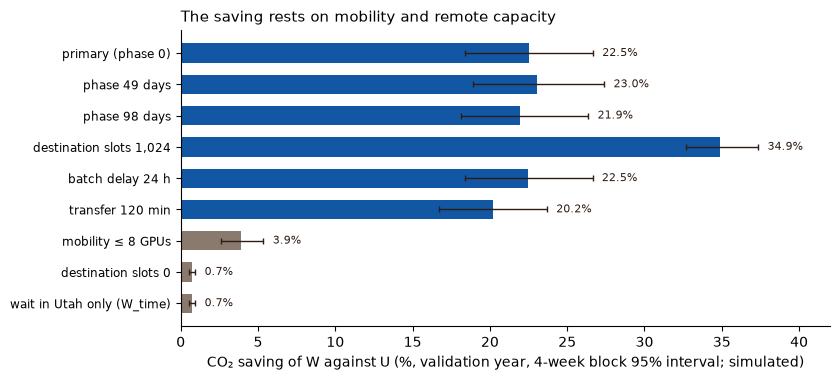

In [4]:
# The saving against U of the weekly-forecast router W in each tested scenario (b = 4, 95% intervals).
bars = [("primary (phase 0)", W_U), ("phase 49 days", ext("phases", "phase_49", "W")),
        ("phase 98 days", ext("phases", "phase_98", "W")),
        ("destination slots 1,024", ext("sensitivities", "dest_slots_1024", "W")),
        ("batch delay 24 h", ext("sensitivities", "batch_delay_24h", "W")),
        ("transfer 120 min", ext("sensitivities", "transfer_120min", "W")),
        ("mobility ≤ 8 GPUs", mob), ("destination slots 0", d0w), ("wait in Utah only (W_time)", wt)]
fig, ax = plt.subplots(figsize=(8.5, 3.9))
y = np.arange(len(bars))[::-1]
for yy, (lab, c) in zip(y, bars):
    s, (lo, hi) = 100 * V(c["saving"]), (100 * x for x in V(c["saving_ci95"]))
    small = lab.startswith(("mobility", "destination slots 0", "wait"))
    ax.barh(yy, s, color="#8a7a6e" if small else "#1157a4", height=0.62)
    ax.errorbar(s, yy, xerr=[[s - lo], [hi - s]], color="#2d1d14", lw=1, capsize=2.5)
    ax.text(hi + 0.6, yy, f"{s:.1f}%", va="center", fontsize=8, color="#2d1d14")
ax.set_yticks(y, [b[0] for b in bars], fontsize=8.5)
ax.set(xlabel="CO₂ saving of W against U (%, validation year, 4-week block 95% interval; simulated)", xlim=(0, 42))
ax.set_title("The saving rests on mobility and remote capacity", loc="left", fontsize=11)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**What the figure shows.** Blue bars are the scenarios where large jobs can still move to spare remote capacity; the saving stays in a band around the primary result, and more remote slots raise it. The grey bars are the three ways of taking moving away: only small jobs may move, no remote slots, or waiting in Utah only. Each leaves a small fraction of the primary saving. Moving, not timing, carries the result, and moving needs mobile large jobs and spare capacity elsewhere.

## 3. Would better (weather-aware) forecasts help?

H is a diagnostic router: the same reservation search as K, W and L, fed the realised (filled) carbon truth instead of a forecast. It is what a perfect carbon forecast, weather-aware or not, would give this router. If H does not beat the fixed ranking S, a better forecast has little room to change the routing result. H is never a contender.

In [5]:
pols = ["H", "S", "K", "W", "L"]
vsU = {p: contrast(p, "U") for p in pols}
hs, hw = contrast("H", "S"), contrast("H", "W")
cov = num("metrics.json#/coverage_stratum/share_flexible_energy_in_coverage")
display(pl.DataFrame([{"router": p, "note": m["policies"][p]["note"], "saving vs U": pct(vsU[p]["saving"], 2),
                       "95% interval": ci_pct(vsU[p]["saving_ci95"], 2), "evidence": vsU[p]["saving"]["evidence"]}
                      for p in pols]))
WEATHER = {
    "statement": (
        f"Perfect carbon foresight (H) saves {sv(vsU['H'])} against U; the fixed clean-region ranking S saves "
        f"{sv(vsU['S'])}. S − H = {tonnes(hs['diff_kg'])} {ci_t(hs['diff_kg_ci95'])}: H does not beat S. "
        f"H does beat the weekly forecast W, by W − H = {tonnes(hw['diff_kg'])} {ci_t(hw['diff_kg_ci95'])} "
        f"({pct(hw['saving'], 2)} of W's CO₂), that is what a perfect forecast adds to this search, and S "
        f"matches H without any forecast. Only {pct(cov, 0)} of flexible energy has its deadline inside issued forecast coverage "
        "at every legal site, so most decisions rest on the tail climatology, not on the forecast."),
    "conclusion": (
        "In this setup even perfect carbon foresight does not beat a fixed ranking, so weather-informed "
        "forecasts are unlikely to change the routing result. They may matter for peak-stress forecasting, "
        "which we did not evaluate."),
    "values": {"H_vs_U": vsU["H"], "S_vs_U": vsU["S"], "W_vs_U": vsU["W"], "L_vs_U": vsU["L"], "H_vs_S": hs,
               "H_vs_W": hw, "share_flexible_energy_in_coverage": cov},
    "decision_ids": ["D-066", "D-068"]}
display(Markdown(WEATHER["statement"] + "\n\n**Conclusion.** " + WEATHER["conclusion"]))

router,note,saving vs U,95% interval,evidence
"""H""","""same search on realized (filled) truth; hindsight diagnostic, never a contender""","""22.61%""","""[18.43, 26.78]""","""simulated"""
"""S""","""fixed clean-region priority by training mean consumed CI""","""22.62%""","""[18.36, 26.82]""","""simulated"""
"""K""","""carbon reservation search on frozen calendar climatology""","""22.41%""","""[18.24, 26.52]""","""simulated"""
"""W""","""carbon reservation search on weekly seasonal forecasts""","""22.51%""","""[18.36, 26.67]""","""simulated"""
"""L""","""carbon reservation search on the learned forecasts (H2 candidate)""","""22.51%""","""[18.32, 26.63]""","""simulated"""


Perfect carbon foresight (H) saves 22.6% [18.4, 26.8] against U; the fixed clean-region ranking S saves 22.6% [18.4, 26.8]. S − H = −0.5 t [−9.9, +8.0]: H does not beat S. H does beat the weekly forecast W, by W − H = +4.5 t [+2.3, +6.9] (0.12% of W's CO₂), that is what a perfect forecast adds to this search, and S matches H without any forecast. Only 29% of flexible energy has its deadline inside issued forecast coverage at every legal site, so most decisions rest on the tail climatology, not on the forecast.

**Conclusion.** In this setup even perfect carbon foresight does not beat a fixed ranking, so weather-informed forecasts are unlikely to change the routing result. They may matter for peak-stress forecasting, which we did not evaluate.

**Why.** Per-job greedy search, H included, is not a cohort optimum: holding the scarce BPAT slots for a cleaner hour pushes later jobs to dirtier sites (`metrics.json`, `framing.greedy_search`). The routing decision is mostly *where*, and the ranking of where (BPAT, then CISO, NEVP, PACE) does not change hour to hour. That is why the owner kept weather out of the frozen forecasts (D-066).

## 4. Not done, and why

In [6]:
NOT_DONE = [{"item": v["item"], "reason": v["reason"],
             "decision_ids": sorted(set(re.findall(r"D-\d{3}", v["reason"])))} for v in ext_["not_run"].values()]
NOT_DONE += [
    {"item": "weather-driven (weather-aware) forecasts",
     "reason": "deferred at the spec gate (the weather manifest was still growing, F8), then not added by the "
               "owner: forecast quality barely affects the routing result (§3) and it would disturb the freeze",
     "decision_ids": ["D-044", "D-066"]},
    {"item": "zero-shot time-series foundation-model forecasts (R4a)",
     "reason": "deferred or cut in the minimal honest core (F9); if revived, it needs independence from the "
               "validation period used for selection and an audit of republished target sources (F12.9)",
     "decision_ids": ["D-045", "D-049"]},
    {"item": "temperature-dependent PUE, curtailment coincidence, wholesale cost, health",
     "reason": "future-work appendix", "decision_ids": ["D-063"]},
]
pl.DataFrame([{**d, "decision_ids": ", ".join(d["decision_ids"])} for d in NOT_DONE])

item,reason,decision_ids
"""shadow-U (no advance booking) sensitivity (F12.7)""","""cut by owner (D-058)""","""D-058"""
"""missingness-blind scheduling sensitivity (F12.1, F13.6)""","""cut by owner (D-058)""","""D-058"""
"""batch delay 0 h (§7)""","""cut by owner (D-058)""","""D-058"""
"""remote transfer time 0 min (§7)""","""cut by owner (D-058)""","""D-058"""
"""remote transfer energy 0% and 20% (§7)""","""cut by owner (D-058)""","""D-058"""
"""active IT power 0.40 and 0.80 kW per GPU slot (§7)""","""cut by owner (D-058)""","""D-058"""
"""remote PUE 1.10 and 1.56 with home fixed (§7)""","""cut by owner (D-058)""","""D-058"""
"""idle IT power 0 and 0.30 kW per slot (§7)""","""cut by owner (D-058)""","""D-058"""
"""no flexible jobs (§7 flexibility share)""","""cut by owner (D-058)""","""D-058"""
"""all candidates flexible (§7 flexibility share)""","""cut by owner (D-058)""","""D-058"""


## 5. Reality-check questions a judge might ask

| Question | Where it is answered |
|---|---|
| Would real jobs really move like this? | §1 *flexible-job share*; §2 *if only small jobs can move* |
| What if the remote region has no spare GPUs? | §1 *spare GPU slots*; §2 *no remote capacity* and the figure |
| Why not just wait for Utah's sunny hours? | §2 *waiting in Utah barely helps* |
| Is the saving real, or an accounting choice? | §1 *consumption basis*; §2 *production basis would flatter hydro* |
| Would better or weather-aware forecasts help? | §3 |
| Does it relieve Utah's grid peak? | §2 *peak relief is tiny* |
| Does a battery help? | §1 *storage*; §2 *storage adds CO₂ on a flat marginal factor* |
| Is it better for water too? | §2 *water: an assumption decides the sign* |
| Are zero deadline misses evidence of reliability? | §1 *advance bookings*, *exact runtimes* |
| Is the illustrative job cherry-picked? | §2 *the literal rule picks a 3-minute job* |
| What did you not run? | §4 |

## 6. Export: `results/assumptions.json`

The register, the negative results, the weather point and the not-done list, with every number as an evidence envelope whose `provenance_id` is the `file#/json/pointer` it was read from (or `derived:op(…)` of two such pointers). `lab/tests/test_assumptions.py` re-reads every pointer and checks the value, unit and evidence. No wall-clock time is written, so a re-run on the same results changes nothing.

In [7]:
QUESTIONS = [
    ("Would real jobs really move like this?", ["flexible_mobile", "mobility_le_8"]),
    ("What if the remote region has no spare GPUs?", ["dest_slots", "dest_capacity_0"]),
    ("Why not just wait for Utah's sunny hours?", ["waiting_in_utah"]),
    ("Is the saving real, or an accounting choice?", ["consumption_basis", "production_flatters_hydro"]),
    ("Would better or weather-aware forecasts help?", ["weather"]),
    ("Does it relieve Utah's grid peak?", ["peak_relief_scale"]),
    ("Does a battery help?", ["storage", "storage_flat_marginal"]),
    ("Is it better for water too?", ["water_hydro", "water_sign"]),
    ("Are zero deadline misses evidence of reliability?", ["bookings", "exact_runtimes"]),
    ("Is the illustrative job cherry-picked?", ["illustrative_literal"]),
    ("What did you not run?", ["not_done"]),
]
OUT = {
    "schema_version": "gridpilot.results.v1",
    "artifact": "assumptions",
    "kind": "register",
    "run_id": RUN_ID,
    "note": ("assumptions register and negative results (D-068); built only from committed results files by "
             "notebooks/40_assumptions_and_reality.ipynb; no simulation, no grid data; every number is read "
             "from the file and JSON pointer in its provenance_id"),
    "evidence_scope": SRC["manifest.json"]["evidence_scope"],
    "sources": {f: {"from": f if f != "water.json" else WATER_FROM, "sha256": SHA[f]} for f in SRC},
    "pending": ([] if "water.json" not in SRC or "pending" not in WATER_FROM else
                [{"item": "water illustration", "status": "pending merge", "pr": WATER_PR, "ref": WATER_REF}])
               + ([] if "water.json" in SRC else
                  [{"item": "water illustration", "status": "pending", "reason": "no committed water.json found"}]),
    "register": REG,
    "negative_results": NEG,
    "weather": WEATHER,
    "not_done": NOT_DONE,
    "questions": [{"question": q, "answered_by": a} for q, a in QUESTIONS],
}
ids = {r["id"] for r in REG} | {n["id"] for n in NEG} | {"weather", "not_done"}
assert all(a in ids for _, refs in QUESTIONS for a in refs if not a.startswith("water")), "question refs"
assert validate_artifact(OUT) == []
write_json_atomic(RESULTS_DIR / "assumptions.json", OUT)
print(f"results/assumptions.json: {len(REG)} register rows, {len(NEG)} negative results, "
      f"{len(NOT_DONE)} not-done items; sha256 {hashlib.sha256((RESULTS_DIR / 'assumptions.json').read_bytes()).hexdigest()[:16]}")

results/assumptions.json: 13 register rows, 11 negative results, 16 not-done items; sha256 7d9a911773c699a2


## Decisions this supports

From the [decision log](../docs/decisions.md):
- **D-068**: this notebook: the assumptions register, the negative results, the weather point and the not-done list, from committed results only.
- **D-056**: the validation result, including waiting in Utah, G, H2 inconclusive and H3 not supported (§2).
- **D-058**: which sensitivities ran (§1, §2) and which were cut (§4).
- **D-066**: weather stays out of the frozen forecasts; perfect foresight does not beat S (§3).
- **D-061, D-067**: storage is illustrative, and its skeptic (flat marginal) result is shown (§1, §2).
- **D-063, D-064**: the water illustration and its caveats; the hydro choice decides the sign (§2).
- **D-054**: the illustrative job's literal rule and its v2 replacement (§2).
- **D-055, D-027**: consumption basis is primary and modeled; the colour midpoint is a display reference (§1).
- **D-048, D-050**: the advance-reservation claim frame (§1).